# Edge Qubits (`q0`, `q_{N-1}`) vs. Middle Qubits (`q1` ... `q_{N-2}`): The "Bowl" Profile

In an open 1D Ising chain of $N$ qubits:
$$\text{q}_0 \longleftrightarrow \text{q}_1 \longleftrightarrow \text{q}_2 \longleftrightarrow \cdots \longleftrightarrow \text{q}_{N-1}$$

not all qubits experience the same amount of noise — even if every physical qubit and coupler on the chip has the exact same error rate!

### Why Do Middle (Interior) Qubits Degrade Faster Than Edge (Boundary) Qubits?
1. **Half as Many 2-Qubit `CZ` Gates on the Edges:**
   * **Edge qubits (`q0` and `q_{N-1}`)** only have **1 neighbor**, so they participate **only in the Even `CZ` layer** and sit completely outside the Odd `CZ` layer ($2 \times$ `CZ` gates per mirrored Trotter step).
   * **Middle qubits (`q1` ... `q_{N-2}`)** have **2 neighbors** (left and right), so they participate in **both the Even and Odd `CZ` layers** ($4 \times$ `CZ` gates per mirrored Trotter step).
2. **Two-Sided Error Lightcone:**
   * Interior qubits absorb propagated Pauli errors from **both** directions along the chain, whereas boundary qubits only have one neighbor that can spread errors into them.

This creates a characteristic **"bowl" (U-shaped) profile** in $\langle Z_i \rangle$ across the chain, where the two ends stay closer to $+1.0$ and the interior sags downward.

In [46]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display

from qiskit import QuantumCircuit
from qiskit.circuit import BoxOp, CircuitInstruction
from qiskit.quantum_info import Pauli, SparsePauliOp, PauliLindbladMap
from qiskit.transpiler import generate_preset_pass_manager

from qiskit_ibm_runtime import QuantumProgram
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh

# Samplomatic
import samplomatic
from samplomatic import Twirl, InjectNoise, ChangeBasis, build
from samplomatic.transpiler import generate_boxing_pass_manager
from samplomatic.utils import find_unique_box_instructions, get_annotation

# Local learner and simulator
from qiskit_aer import AerSimulator
from qiskit_noise_learning.aer_executor import AerExecutor
from qiskit_noise_learning.noise_learner import LearningOptions, NoiseLearner

In [47]:
def synthetic_noise_dict(
    unique_layers,
    seed: int = 42,
    mean_rate_1q: float = 2e-3,
    mean_rate_2q: float = 1e-2,
    mean_spam_rate: float = 1e-2,
) -> dict[str, PauliLindbladMap]:
    """Build synthetic Pauli-Lindblad noise maps for local AerExecutor noise learning."""
    rng = np.random.default_rng(seed)
    noise_dict = {}

    # Keep only gate boxes carrying InjectNoise
    unique_layers[:] = [
        inst for inst in unique_layers
        if get_annotation(inst.operation, InjectNoise) is not None
    ]

    # Collect all active physical Qubit objects across all layers in ascending index order
    all_qubits = sorted(
        {q for inst in unique_layers for q in inst.qubits if q._index is not None},
        key=lambda q: q._index,
    )
    all_active_qubits = {q._index for q in all_qubits}

    for idx, inst in enumerate(unique_layers):
        orig_phys = (inst.operation.body.metadata or {}).get(
            "orig_phys_qubits", sorted(q._index for q in inst.qubits)
        )
        if list(inst.qubits) != all_qubits:
            old_body = inst.operation.body
            q_map = [all_qubits.index(q) for q in inst.qubits]
            new_body = QuantumCircuit(len(all_qubits), old_body.num_clbits)
            new_body.compose(
                old_body,
                qubits=q_map,
                clbits=list(range(old_body.num_clbits)),
                inplace=True,
            )
            new_body.metadata = {"orig_phys_qubits": orig_phys}
            new_box = BoxOp(new_body, annotations=inst.operation.annotations)
            inst = CircuitInstruction(new_box, tuple(all_qubits), inst.clbits)
            unique_layers[idx] = inst
        else:
            inst.operation.body.metadata = {"orig_phys_qubits": orig_phys}

        inj_ann = get_annotation(inst.operation, InjectNoise)
        if inj_ann is None:
            continue
        tag_ref = inj_ann.ref
        num_layer_qubits = len(inst.qubits)
        sparse_terms = []

        # 1Q Pauli-Lindblad rates on each local qubit index
        for local_i in range(num_layer_qubits):
            for pauli in ("X", "Y", "Z"):
                r1 = float(rng.uniform(0.5 * mean_rate_1q, 1.5 * mean_rate_1q))
                sparse_terms.append((pauli, [local_i], r1))

        # 2Q Pauli-Lindblad rates on each 2Q gate inside the box body
        box_circuit = inst.operation.body
        for sub_inst in box_circuit.data:
            if len(sub_inst.qubits) == 2:
                l0 = box_circuit.find_bit(sub_inst.qubits[0]).index
                l1 = box_circuit.find_bit(sub_inst.qubits[1]).index
                for pauli_2q, scale in [("ZZ", 1.0), ("XX", 0.5), ("YY", 0.5), ("IZ", 0.5), ("ZI", 0.5)]:
                    r2 = float(rng.uniform(0.5 * mean_rate_2q, 1.5 * mean_rate_2q) * scale)
                    sparse_terms.append((pauli_2q, [l0, l1], r2))

        noise_dict[tag_ref] = PauliLindbladMap.from_sparse_list(
            sparse_terms, num_qubits=num_layer_qubits
        )

    # SPAM noise for AerExecutor's active learning qubits
    num_active = len(all_active_qubits)
    if num_active > 0:
        p_terms = [("X", [i], float(rng.uniform(0.5 * mean_spam_rate, 1.5 * mean_spam_rate))) for i in range(num_active)]
        m_terms = [("X", [i], float(rng.uniform(0.5 * mean_spam_rate, 1.5 * mean_spam_rate))) for i in range(num_active)]
        noise_dict["P"] = PauliLindbladMap.from_sparse_list(p_terms, num_qubits=num_active)
        noise_dict["M"] = PauliLindbladMap.from_sparse_list(m_terms, num_qubits=num_active)

    return noise_dict

In [48]:
def local_result_to_dict(noise_result, unique_layers):
    """
    Local equivalent of NoiseLearnerV3Results.to_dict(unique_layers, unique_refs=False).
    Slices the 156-qubit global PauliLindbladMap down to the exact local qubits of each box.
    """
    global_noise_dict = noise_result.to_dict()
    refs_to_noise = {}

    for inst in unique_layers:
        inj_ann = get_annotation(inst.operation, InjectNoise)
        if inj_ann is None:
            continue
        ref = inj_ann.ref
        if ref in global_noise_dict:
            global_map = global_noise_dict[ref]
            box_body = inst.operation.body
            orig_phys = (box_body.metadata or {}).get("orig_phys_qubits")
            if orig_phys is not None:
                phys_qubits = orig_phys
            else:
                phys_qubits = sorted(q._index for q in inst.qubits)

            if global_map.num_qubits > len(phys_qubits):
                refs_to_noise[ref] = global_map.keep_qubits(phys_qubits)
            else:
                refs_to_noise[ref] = global_map

    return refs_to_noise

In [49]:
def construct_ising_circuit(
    num_qubits: int,
    num_trotter_steps: int,
    rx_angle: float,
    barrier: bool = True,
) -> QuantumCircuit:
    """Construct a Trotterized 1D Transverse-Field Ising circuit using Sdg + CZ blocks."""
    qc = QuantumCircuit(num_qubits)
    for _ in range(num_trotter_steps):
        qc.rx(rx_angle, range(num_qubits))
        if barrier:
            qc.barrier()
        for first_qubit in (1, 2):
            for idx in range(first_qubit, num_qubits, 2):
                qc.sdg([idx - 1, idx])
                qc.cz(idx - 1, idx)
        if barrier:
            qc.barrier()
    return qc

## Part 1: Counting `CZ` Gates per Qubit on a 6-Qubit Chain

Let's use a **6-qubit chain** (`q0` to `q5`) so we have **2 Edge Qubits (`q0`, `q5`)** and **4 Middle Qubits (`q1`, `q2`, `q3`, `q4`)**. Before running any simulation, we can directly count how many `CZ` gates touch each qubit in a 2-step mirror circuit and inspect the two unique `BoxOp` layers:

CZ gate count per qubit in 2-step Mirror Ising circuit:
  Qubit q0 [EDGE  (1 neighbor) ]: 4 CZ gates
  Qubit q1 [MIDDLE (2 neighbors)]: 8 CZ gates
  Qubit q2 [MIDDLE (2 neighbors)]: 8 CZ gates
  Qubit q3 [MIDDLE (2 neighbors)]: 8 CZ gates
  Qubit q4 [MIDDLE (2 neighbors)]: 8 CZ gates
  Qubit q5 [EDGE  (1 neighbor) ]: 4 CZ gates


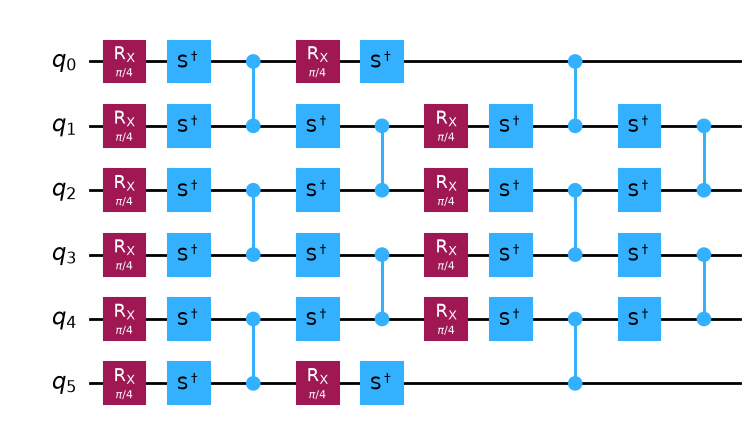

In [50]:
backend = FakeMarrakesh()
isa_pm = generate_preset_pass_manager(backend=backend, optimization_level=0)

noise_learning_boxing_pm = generate_boxing_pass_manager(
    enable_gates=True,
    enable_measures=True,
    twirling_strategy="active",
    inject_noise_targets="gates",
    inject_noise_strategy="no_modification",
)

num_qubits = 6
rx_angle = np.pi / 4

ising_6q = construct_ising_circuit(
    num_qubits=num_qubits,
    num_trotter_steps=2,
    rx_angle=rx_angle,
    barrier=False,
)

mirror_6q = QuantumCircuit(num_qubits)
mirror_6q.compose(ising_6q, inplace=True)
mirror_6q.barrier()
mirror_6q.compose(ising_6q.inverse(), inplace=True)
mirror_6q.measure_all()

# Count how many CZ gates act on each qubit in the 2-step mirror circuit
cz_counts = [0] * num_qubits
for inst in mirror_6q.data:
    if inst.operation.name == "cz":
        for q in inst.qubits:
            cz_counts[mirror_6q.find_bit(q).index] += 1

print("CZ gate count per qubit in 2-step Mirror Ising circuit:")
for q, count in enumerate(cz_counts):
    role = "EDGE  (1 neighbor) " if q in (0, num_qubits - 1) else "MIDDLE (2 neighbors)"
    print(f"  Qubit q{q} [{role}]: {count} CZ gates")

display(ising_6q.draw("mpl", fold=-1))

## Part 2: Learn the 6-Qubit Layer Noise Models Locally

Notice that when we box `mirror_6q`:
* **Even Layer (`(0,1), (2,3), (4,5)`):** Acts on **all 6 qubits** (`q0` through `q5`).
* **Odd Layer (`(1,2), (3,4)`):** Acts **only on the 4 middle qubits** (`q1, q2, q3, q4`) — the edge qubits `q0` and `q5` aren't even in this box!

In [51]:
mirror_6q_isa = isa_pm.run(mirror_6q)
boxed_6q = noise_learning_boxing_pm.run(mirror_6q_isa)

unique_layers_6q = find_unique_box_instructions(
    boxed_6q,
    normalize_annotations=None,
    undress_boxes=True,
)

toy_noise_dict_6q = synthetic_noise_dict(unique_layers_6q)

nl_options_6q = LearningOptions(
    num_randomizations=8,
    shots_per_randomization=32,
    fragment_depths=[1, 2, 4],
)

aer_executor_6q = AerExecutor(
    AerSimulator(),
    noise_dict=toy_noise_dict_6q,
    warn_absent=False,
    #root_seed=2026,
)

learner_6q = NoiseLearner(
    backend,
    options=nl_options_6q,
    executor=aer_executor_6q,
)

learner_job_6q = learner_6q.run(unique_layers_6q)
toy_noise_result_6q = learner_job_6q.result()
refs_to_noise_6q = local_result_to_dict(toy_noise_result_6q, unique_layers_6q)

print(f"Learned noise for {len(refs_to_noise_6q)} unique layers:")
for ref, plm in refs_to_noise_6q.items():
    orig_q = next(
        inst.operation.body.metadata["orig_phys_qubits"]
        for inst in unique_layers_6q
        if get_annotation(inst.operation, InjectNoise).ref == ref
    )
    print(f"  Layer '{ref}': {plm.num_qubits}-qubit PauliLindbladMap acting on physical qubits {orig_q}")

Learned noise for 2 unique layers:
  Layer 'radfA': 6-qubit PauliLindbladMap acting on physical qubits [0, 1, 2, 3, 4, 5]
  Layer 'raa1A': 4-qubit PauliLindbladMap acting on physical qubits [1, 2, 3, 4]


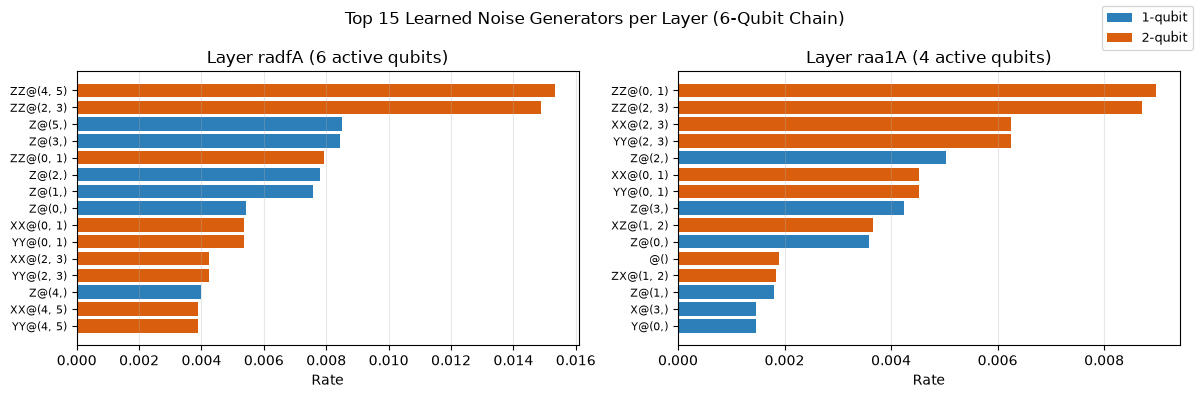

In [52]:
# Plot the top 15 learned noise generators per layer
fig, axes = plt.subplots(1, len(refs_to_noise_6q), figsize=(12, 4))
if len(refs_to_noise_6q) == 1:
    axes = [axes]

for ax, (ref, plm) in zip(axes, refs_to_noise_6q.items()):
    gens = sorted(plm.to_sparse_list(), key=lambda g: -abs(g[2]))[:15]
    labels = [f"{p}@{tuple(q)}" for p, q, _ in gens]
    rates = [r for _, _, r in gens]
    colors = ["#2c7fb8" if len(p) == 1 else "#d95f0e" for p, _, _ in gens]
    ax.barh(range(len(labels)), rates, color=colors)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("Rate")
    ax.set_title(f"Layer {ref} ({plm.num_qubits} active qubits)")
    ax.grid(axis="x", alpha=0.3)

fig.legend(
    handles=[
        Patch(facecolor="#2c7fb8", label="1-qubit"),
        Patch(facecolor="#d95f0e", label="2-qubit"),
    ],
    loc="upper right",
    fontsize=9,
)
fig.suptitle("Top 15 Learned Noise Generators per Layer (6-Qubit Chain)")
plt.tight_layout()
plt.show()

## Part 3: Comparing Edge vs. Middle Qubits Across Trotter Depths (`steps = 1, 2, 3, 4`)

Because every Trotter step uses the **exact same 2 unique `CZ` layers**, we can reuse `refs_to_noise_6q` to run mirror circuits of depth `num_trotter_steps = 1, 2, 3, 4` and watch the "bowl" shape deepen as errors accumulate in the middle of the chain:

In [53]:
trotter_depths = [1, 2, 3, 4]
z_by_depth = []

for steps in trotter_depths:
    ising_step = construct_ising_circuit(
        num_qubits=num_qubits,
        num_trotter_steps=steps,
        rx_angle=rx_angle,
        barrier=False,
    )
    mirror_step = QuantumCircuit(num_qubits)
    mirror_step.compose(ising_step, inplace=True)
    mirror_step.barrier()
    mirror_step.compose(ising_step.inverse(), inplace=True)
    mirror_step.measure_all()

    boxed_step = noise_learning_boxing_pm.run(isa_pm.run(mirror_step))
    template_step, samplex_step = build(boxed_step)

    samplex_args_step = (
        samplex_step.inputs()
        .make_broadcastable()
        .bind(pauli_lindblad_maps=refs_to_noise_6q)
    )

    prog_step = QuantumProgram(shots=64)
    prog_step.append_samplex_item(
        circuit=template_step,
        samplex=samplex_step,
        samplex_arguments=samplex_args_step,
        shape=(32,),
    )

    res_step = aer_executor_6q.run(prog_step).result()[0]
    corrected_step = np.bitwise_xor(res_step["meas"], res_step["measurement_flips.meas"])
    z_vals_step = 1 - 2 * corrected_step.astype(np.int8)
    z_means_step = z_vals_step.reshape(-1, z_vals_step.shape[-1]).mean(axis=0)
    z_by_depth.append(z_means_step)

z_by_depth = np.array(z_by_depth)  # shape: (4 depths, 6 qubits)

edge_idxs = [0, num_qubits - 1]
middle_idxs = list(range(1, num_qubits - 1))

edge_means = z_by_depth[:, edge_idxs].mean(axis=1)
middle_means = z_by_depth[:, middle_idxs].mean(axis=1)

print(f"{'Trotter Steps':<15}{'Edge Mean ⟨Z⟩ (q0, q5)':<26}{'Middle Mean ⟨Z⟩ (q1..q4)':<28}{'Edge - Middle Gap'}")
print("-" * 85)
for steps, e_m, m_m in zip(trotter_depths, edge_means, middle_means):
    print(f"{steps:<15}{e_m:<26.4f}{m_m:<28.4f}{e_m - m_m:+.4f}")

Trotter Steps  Edge Mean ⟨Z⟩ (q0, q5)    Middle Mean ⟨Z⟩ (q1..q4)    Edge - Middle Gap
-------------------------------------------------------------------------------------
1              0.9390                    0.7939                      +0.1450
2              0.7827                    0.7993                      -0.0166
3              0.6724                    0.5393                      +0.1331
4              0.6704                    0.4006                      +0.2698


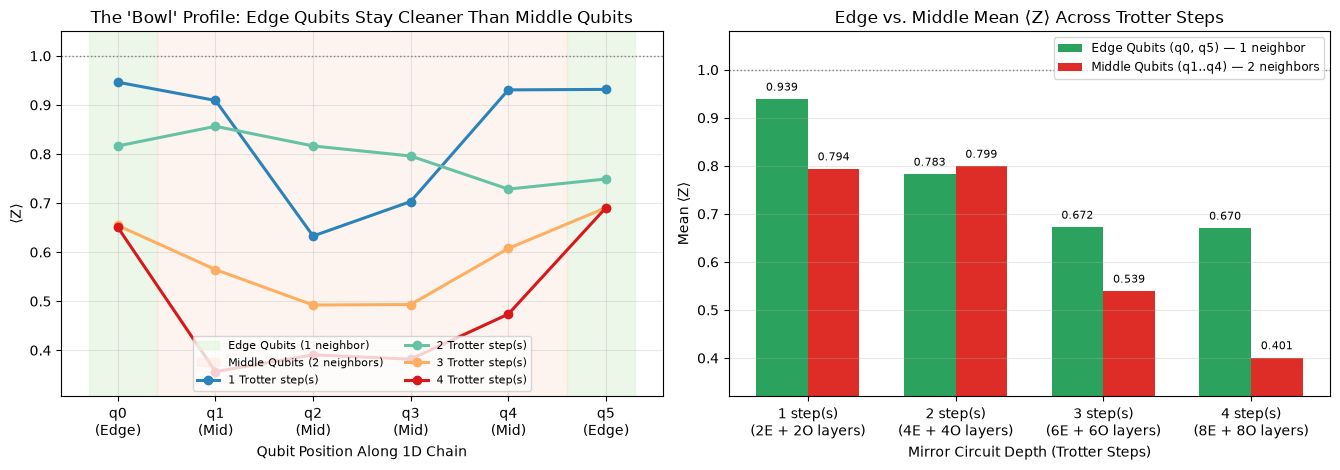

In [54]:
# Visualize: (1) The "Bowl" Profile Across the Chain & (2) Edge vs. Middle Decay with Depth
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

qubits_x = np.arange(num_qubits)
depth_colors = ["#2b83ba", "#66c2a5", "#fdae61", "#d7191c"]

# Shade the Edge qubit regions on the left plot
ax1.axvspan(-0.3, 0.4, color="#e5f5e0", alpha=0.7, label="Edge Qubits (1 neighbor)")
ax1.axvspan(num_qubits - 1.4, num_qubits - 0.7, color="#e5f5e0", alpha=0.7)
ax1.axvspan(0.4, num_qubits - 1.4, color="#fee0d2", alpha=0.35, label="Middle Qubits (2 neighbors)")

for i, (steps, col) in enumerate(zip(trotter_depths, depth_colors)):
    ax1.plot(
        qubits_x,
        z_by_depth[i],
        marker="o",
        lw=2.2,
        color=col,
        label=f"{steps} Trotter step(s)",
    )

ax1.axhline(1.0, color="gray", ls=":", lw=1)
ax1.set_xticks(qubits_x)
ax1.set_xticklabels([f"q{q}\n({'Edge' if q in edge_idxs else 'Mid'})" for q in qubits_x])
ax1.set_xlabel("Qubit Position Along 1D Chain")
ax1.set_ylabel("⟨Z⟩")
ax1.set_ylim(min(0.35, float(z_by_depth.min()) - 0.05), 1.05)
ax1.set_title("The 'Bowl' Profile: Edge Qubits Stay Cleaner Than Middle Qubits")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8, loc="lower center", ncol=2)

# Right panel: Edge Mean vs Middle Mean as a function of Trotter steps
x_pos = np.arange(len(trotter_depths))
bar_w = 0.35

bars_edge = ax2.bar(
    x_pos - bar_w / 2,
    edge_means,
    width=bar_w,
    color="#2ca25f",
    label="Edge Qubits (q0, q5) — 1 neighbor",
)
bars_mid = ax2.bar(
    x_pos + bar_w / 2,
    middle_means,
    width=bar_w,
    color="#de2d26",
    label="Middle Qubits (q1..q4) — 2 neighbors",
)

for b in list(bars_edge) + list(bars_mid):
    h = b.get_height()
    ax2.text(b.get_x() + b.get_width() / 2, h + 0.012, f"{h:.3f}", ha="center", va="bottom", fontsize=8)

ax2.axhline(1.0, color="gray", ls=":", lw=1)
ax2.set_xticks(x_pos)
ax2.set_xticklabels([f"{s} step(s)\n({2*s}E + {2*s}O layers)" for s in trotter_depths])
ax2.set_xlabel("Mirror Circuit Depth (Trotter Steps)")
ax2.set_ylabel("Mean ⟨Z⟩")
ax2.set_ylim(min(0.35, float(middle_means.min()) - 0.08), 1.08)
ax2.set_title("Edge vs. Middle Mean ⟨Z⟩ Across Trotter Steps")
ax2.grid(axis="y", alpha=0.3)
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()